# Встреча 3. Запуск и доверие к данным: теория

> **Время:** 35 минут · **Дальше:** `practice.ipynb` · **Данные:** `../data/checkout_ab.csv`

Дизайн-док готов, тест чекаута запущен: 20% трафика на новую страницу, 14 дней. Прежде чем считать эффект, надо убедиться, что платформа честно раздала группы и ничего не потеряла. Сломанный сплит или потерянные события дают «эффект», которого нет, или прячут настоящий. Никакая статистика после этого не спасёт.

| Блок | Тезис | Минут |
| --- | --- | :---: |
| 1 | Сплит — это `hash(соль:user_id)` → бакет; ломается плохим хешем и общей солью | 10 |
| 2 | A/A и SRM — две проверки исправности: p-value A/A равномерны, доли групп совпадают с планом | 13 |
| 3 | Потери телеметрии и неверный триггер смещают эффект; честный триггер даёт мощность | 12 |

### Библиотеки и функции

In [1]:
import hashlib
import zlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data/checkout_ab.csv')
SALT, SHARE_B = 'checkout-v2', 0.20


def md5_hash(ids, salt: str) -> np.ndarray:
    """MD5 строки 'соль:id' → целое (первые 15 hex-символов)."""
    return np.array([int(hashlib.md5(f'{salt}:{i}'.encode()).hexdigest()[:15], 16) for i in ids], dtype=np.int64)


def crc32_hash(ids, salt: str) -> np.ndarray:
    return np.array([zlib.crc32(f'{salt}:{i}'.encode()) for i in ids], dtype=np.int64)


def java_hash(ids, salt: str) -> np.ndarray:
    """Java String.hashCode() строки 'соль:id' (32 бита, беззнаково), векторно для id одной длины."""
    mask = np.uint64(0xFFFFFFFF)
    value = np.uint64(0)
    for ch in f'{salt}:'.encode():
        value = (value * np.uint64(31) + np.uint64(ch)) & mask
    value = np.full(len(ids), value, dtype=np.uint64)
    digits = np.array([list(s) for s in np.char.mod('%d', ids)]).astype(np.uint64) + np.uint64(48)
    for j in range(digits.shape[1]):
        value = (value * np.uint64(31) + digits[:, j]) & mask
    return value.astype(np.int64)


def srm_pvalue(counts, shares) -> float:
    """χ² согласия: наблюдаемые размеры групп против планового сплита."""
    counts = np.asarray(counts, dtype=float)
    return stats.chisquare(counts, counts.sum() * np.asarray(shares)).pvalue

## Блок 1. Сплитование

**Тезис.** Группу не хранят, а вычисляют: $\text{бакет} = \text{hash}(\text{соль} : \text{user\_id}) \bmod 10\,000$, бакеты $0\ldots1999$ — вариант B (20%). Так группа одна и та же в сервисе, в SDK и в SQL аналитика. От сплита требуем трёх свойств:

1. **не зависит от пользователя:** порядок регистрации, шард, устройство не влияют на группу;
2. **детерминирован:** тот же пользователь всегда в той же группе;
3. **независим между тестами:** группы этого теста не связаны с группами прошлых и соседних.

Путь четырёх соседних пользователей чекаута — и сверка с логом: пересчитанная группа обязана совпасть с записанной.

In [2]:
rows = []
for uid in [1_000_123, 1_000_124, 1_000_125, 1_000_126]:
    key = f'{SALT}:{uid}'
    digest = hashlib.md5(key.encode()).hexdigest()
    bucket = int(digest, 16) % 10_000
    rows.append({'строка': key, 'md5 (начало)': digest[:10] + '…', 'бакет': bucket, 'группа': 'B' if bucket < 2_000 else 'A'})
display(pd.DataFrame(rows))

raw = pd.read_csv(DATA)
recomputed = np.where(np.array([int(hashlib.md5(f'{SALT}:{u}'.encode()).hexdigest(), 16) % 10_000 for u in raw['user_id']]) < 2_000, 'B', 'A')
print(f"Строк в логе: {len(raw):,}; группа в логе ≠ пересчитанной: {(raw['group'] != recomputed).sum()}".replace(',', ' '))

,строка,md5 (начало),бакет,группа
0,checkout-v2:1000123,d7426e602e…,1263,B
1,checkout-v2:1000124,7d385e50a6…,4328,A
2,checkout-v2:1000125,8308ef207b…,4002,A
3,checkout-v2:1000126,0523295f88…,295,B


Строк в логе: 105 330; группа в логе ≠ пересчитанной: 60


Соседние `user_id` разлетаются по случайным бакетам. В логе 60 строк, где записанная группа не совпадает с хешем — это ровно 60 «пользователей в обеих группах», которые разберём на практике. Сверка с хешем — первая проверка лога.

**Как ломается.** Три типовые поломки, и ни одну не видно по долям групп.

* **Плохой хеш.** У CRC32 и Java `hashCode` младшие биты зависят от входа линейно. Соль меняет число, но не «перемешивает» его: группы двух тестов с разными солями оказываются связаны.
* **Одна соль на два теста.** В новый тест попадают те же люди, что в прошлый, вместе с остаточным эффектом прошлого теста.
* **Нет двойного посола.** Трафик делят между тестами солью слоя, а внутри теста — той же солью: тогда все пользователи `exp_1` окажутся в B, а все `exp_2` — в A. Соль слоя и соль варианта должны быть разными.

Мера связи групп двух тестов — $\varphi$ таблицы сопряжённости 2×2: 0 — независимы, 1 — одна группа определяет другую. Считаем на 20 тыс. последовательных `user_id` для трёх пар солей.

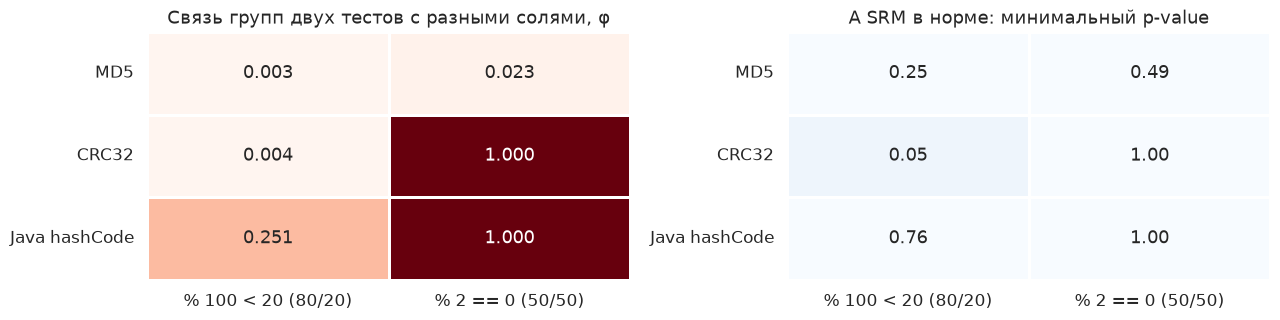

φ: {'MD5': {'% 100 < 20 (80/20)': 0.003, '% 2 == 0 (50/50)': 0.023}, 'CRC32': {'% 100 < 20 (80/20)': 0.004, '% 2 == 0 (50/50)': 1.0}, 'Java hashCode': {'% 100 < 20 (80/20)': 0.251, '% 2 == 0 (50/50)': 1.0}}


In [3]:
ids = np.arange(1_000_000, 1_020_000)
HASHES = {'MD5': md5_hash, 'CRC32': crc32_hash, 'Java hashCode': java_hash}
RULES = {'% 2 == 0 (50/50)': lambda v: v % 2 == 0, '% 100 < 20 (80/20)': lambda v: v % 100 < 20}
SALT_PAIRS = [(f'exp_{k}a', f'exp_{k}b') for k in range(3)]


def phi(a: np.ndarray, b: np.ndarray) -> float:
    return abs(np.corrcoef(a, b)[0, 1])


phi_table, srm_table = {}, {}
for hash_name, fn in HASHES.items():
    hashed = [(fn(ids, s1), fn(ids, s2)) for s1, s2 in SALT_PAIRS]
    for rule_name, rule in RULES.items():
        share = 0.5 if '50' in rule_name else 0.2
        phi_table[(hash_name, rule_name)] = max(phi(rule(h1), rule(h2)) for h1, h2 in hashed)
        srm_table[(hash_name, rule_name)] = min(srm_pvalue([(~rule(h1)).sum(), rule(h1).sum()], [1 - share, share]) for h1, _ in hashed)

phi_map = pd.Series(phi_table).unstack().reindex(list(HASHES))
srm_map = pd.Series(srm_table).unstack().reindex(list(HASHES))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
sns.heatmap(phi_map, annot=True, fmt='.3f', cmap='Reds', vmin=0, vmax=1, cbar=False, linewidths=1, ax=axes[0])
axes[0].set_title('Связь групп двух тестов с разными солями, φ')
sns.heatmap(srm_map, annot=True, fmt='.2f', cmap='Blues_r', vmin=0, vmax=0.05, cbar=False, linewidths=1, ax=axes[1])
axes[1].set_title('А SRM в норме: минимальный p-value')
for ax in axes:
    ax.set_ylabel('')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()
print('φ:', phi_map.round(3).to_dict('index'))

In [4]:
base = np.arange(1_000_000, 1_050_000)
layer = md5_hash(base, 'layer-1') % 2 == 0                       # слой делит трафик: exp_1 / exp_2
same = layer                                                      # внутри — та же соль слоя
own_1, own_2 = md5_hash(base, 'exp_1') % 2 == 0, md5_hash(base, 'exp_2') % 2 == 0
print(f"Одна соль на слой и вариант: доля B в exp_1 = {same[layer].mean():.2f}, в exp_2 = {same[~layer].mean():.2f}")
print(f"Двойной посол:               доля B в exp_1 = {own_1[layer].mean():.2f}, в exp_2 = {own_2[~layer].mean():.2f}")
print(f"Повтор соли прошлого теста: совпадение групп = {(own_1 == own_1).mean():.0%}; "
      f"с новой солью = {(own_1 == own_2).mean():.0%} (при независимости 50%)")

Одна соль на слой и вариант: доля B в exp_1 = 1.00, в exp_2 = 0.00
Двойной посол:               доля B в exp_1 = 0.50, в exp_2 = 0.50
Повтор соли прошлого теста: совпадение групп = 100%; с новой солью = 50% (при независимости 50%)


* **MD5** даёт независимые группы при любом правиле: $\varphi \le 0.02$ — на уровне шума для 20 тыс. пользователей.
* **CRC32 и Java `hashCode` при `% 2`** — $\varphi = 1$: соль не работает, два «разных» теста идут на одних и тех же людях.
* **При `% 100 < 20`** CRC32 становится чистым, а у Java `hashCode` остаётся связь $\varphi \approx 0.25$. Оценивать надо связку «хеш + правило бакетов + формат id», а не хеш в отрыве.
* **SRM этого не видит:** доли групп идеальны. Нужна отдельная проверка — A/A по солям и таблица сопряжённости с прошлыми тестами.

## Блок 2. A/A и SRM

**Тезис.** Две проверки исправности, и обе — до анализа эффекта.

**SRM** (sample ratio mismatch) — фактический сплит не совпадает с плановым. Проверяем критерием согласия $\chi^2$ против *заданного* сплита 80/20, а не против 50/50 и не тестом «A против B»:

$$
\chi^2 = \sum_{g \in \{A, B\}} \frac{(n_g - N s_g)^2}{N s_g}, \qquad s_A = 0.8,\ s_B = 0.2,\ \text{df} = 1.
$$

Порог строгий — $p < 0.001$: проверку гоняют каждый день, и ложная тревога дорога. Но SRM, найденный при этом пороге, «на случайность» не списывают: эффект не считаем, пока не найдена причина.

**Множественные A/A** проверяют сам механизм сплита: прогоняем сотни A/A на исторических данных с разными солями. Если сплит случаен, p-value равномерны на $[0, 1]$ и значимы ~5%. Неравномерность в любую сторону — поломка.

Сначала SRM чекаута на очищенных данных (как чистить — первое задание практики).

In [5]:
clean = raw.drop_duplicates()
in_both = clean.groupby('user_id')['group'].nunique().gt(1)
clean = clean[~clean['user_id'].isin(in_both[in_both].index)]
counts = clean['group'].value_counts().reindex(['A', 'B'])
print(f"A: {counts['A']:,}  B: {counts['B']:,}  доля B = {counts['B'] / counts.sum():.4f}".replace(',', ' '))
print(f"SRM против 80/20: p = {srm_pvalue(counts, [0.8, 0.2]):.2f}")
print(f"Ошибка: χ² против 50/50 даёт p = {srm_pvalue(counts, [0.5, 0.5]):.1g} — «SRM» на ровном месте")

A: 83 878  B: 21 082  доля B = 0.2009
SRM против 80/20: p = 0.49
Ошибка: χ² против 50/50 даёт p = 0 — «SRM» на ровном месте


Сплит чекаута в норме. Теперь A/A по солям на плохом и хорошем хеше. Сценарий: на тех же пользователях до нас шёл тест `checkout-v1`, и у его варианта остался небольшой эффект (+0.15σ). Прогоняем 200 A/A с солями `aa_0 … aa_199` на 4 тыс. последовательных `user_id` и считаем долю $p < 0.05$.

Справа — мощность SRM: какую долю потерянных пользователей B проверка ловит при $p < 0.001$ на объёме двух дней (15 тыс.) и всего теста (105 тыс.).

MD5            доля p < 0.05: 3.0%; разброс доли B: 0.0071 (ожидается 0.0063)


Java hashCode  доля p < 0.05: 26.0%; разброс доли B: 0.0013 (ожидается 0.0063)


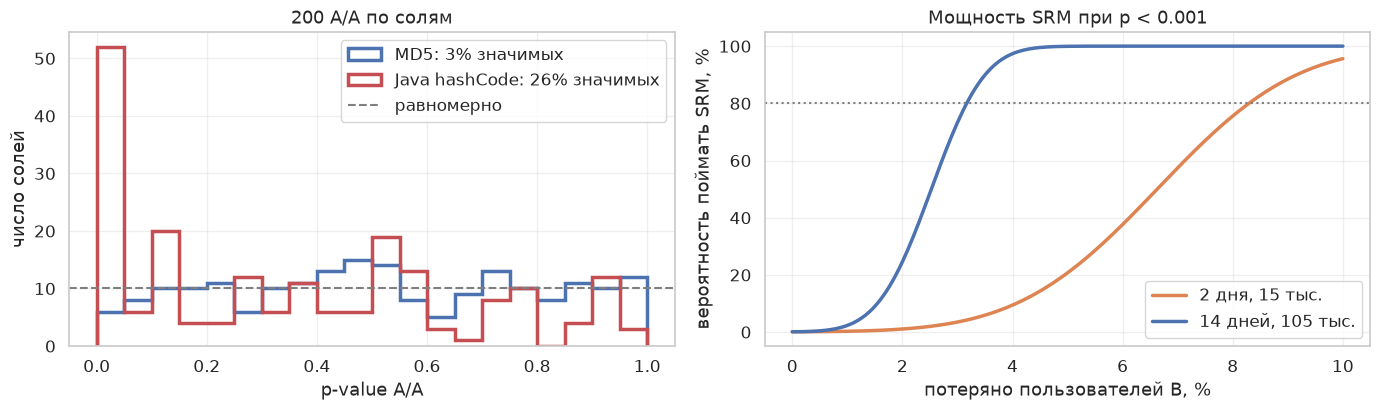

n = 15 000: 80% мощности при потере 8.3% пользователей B
n = 105 000: 80% мощности при потере 3.2% пользователей B


In [6]:
rng = np.random.default_rng(3)
aa_ids = np.arange(1_000_000, 1_004_000)
noise = rng.normal(0, 1, aa_ids.size)

aa = {}
for name, fn in {'MD5': md5_hash, 'Java hashCode': java_hash}.items():
    previous_b = fn(aa_ids, 'checkout-v1') % 100 < 20
    metric = noise + 0.15 * previous_b                       # остаточный эффект прошлого теста
    pvalues, shares = [], []
    for k in range(200):
        b = fn(aa_ids, f'aa_{k}') % 100 < 20
        pvalues.append(stats.ttest_ind(metric[b], metric[~b], equal_var=False).pvalue)
        shares.append(b.mean())
    aa[name] = (np.array(pvalues), np.array(shares))
    print(f"{name:14s} доля p < 0.05: {np.mean(aa[name][0] < 0.05):.1%}; "
          f"разброс доли B: {np.std(shares):.4f} (ожидается {np.sqrt(0.16 / aa_ids.size):.4f})")


def srm_power(lost: np.ndarray, n: int, share: float = 0.2, alpha: float = 0.001) -> np.ndarray:
    """Вероятность поймать SRM, если теряется доля lost пользователей B."""
    observed = share * (1 - lost) / (1 - share * lost)
    se = np.sqrt(share * (1 - share) / n)
    z = stats.norm.isf(alpha / 2)
    shift = (observed - share) / se
    return stats.norm.cdf(-z - shift) + stats.norm.sf(z - shift)


lost = np.linspace(0, 0.10, 201)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for (name, (pvalues, _)), color in zip(aa.items(), [BLUE, RED]):
    axes[0].hist(pvalues, bins=20, range=(0, 1), histtype='step', linewidth=2.5, color=color,
                 label=f'{name}: {np.mean(pvalues < 0.05):.0%} значимых')
axes[0].axhline(200 / 20, color=GRAY, linestyle='--', label='равномерно')
axes[0].set_xlabel('p-value A/A')
axes[0].set_ylabel('число солей')
axes[0].set_title('200 A/A по солям')
axes[0].legend()
for n, color, label in [(15_000, ORANGE, '2 дня, 15 тыс.'), (105_000, BLUE, '14 дней, 105 тыс.')]:
    axes[1].plot(lost * 100, srm_power(lost, n) * 100, color=color, linewidth=2.5, label=label)
axes[1].axhline(80, color=GRAY, linestyle=':')
axes[1].set_xlabel('потеряно пользователей B, %')
axes[1].set_ylabel('вероятность поймать SRM, %')
axes[1].set_title('Мощность SRM при p < 0.001')
axes[1].legend()
plt.tight_layout()
plt.show()
for n in [15_000, 105_000]:
    print(f"n = {n:,}: 80% мощности при потере {lost[np.argmax(srm_power(lost, n) >= 0.8)]:.1%} пользователей B".replace(',', ' '))

* **MD5:** p-value равномерны, значимых 3% — в пределах шума для 200 солей.
* **Java `hashCode`:** значимых 26%, каждый четвёртый A/A «находит» эффект. Группы A/A связаны с группами прошлого теста, и его остаточный эффект выглядит как «эффект» A/A. Заодно доля B у него подозрительно стабильна — разброс в 5 раз меньше биномиального. Слишком ровные группы — такой же сигнал поломки, как перекошенные.
* **SRM-проверка чувствительна:** с мощностью 80% она ловит потерю 3.2% пользователей B на всём тесте и 8.3% — на двух днях. Значит, SRM почти всегда означает реальную поломку, а не невезение.

**Пять типовых причин SRM** — и где их искать:

| Причина | Механизм | Признак в данных |
| --- | --- | --- |
| Баг назначения | SDK при ошибке кладёт пользователя в контроль; разные реализации хеша | Дефицит B в одном устройстве / версии; A больше плана; группа ≠ пересчитанный хеш |
| Ботфильтр / антифрод после назначения | Фильтр срабатывает по поведению, а вариант меняет поведение | Со всеми строками сплит честный, после фильтра — нет; доля ботов разная по группам |
| Потери телеметрии в одной группе | Вариант шлёт события иначе (пачкой, позже, другой библиотекой) | Дефицит равномерный по срезам; другое распределение задержки события; обрыв на окне пайплайна |
| Триггер / редирект только в одной ветке | В B лишний переход или другое условие логирования | Дефицит в одном источнике (реклама, диплинки); лишняя задержка в B |
| Неверная дата старта / кэш | Вариант включился позже, CDN отдавал старую страницу | Дефицит B только в первые дни, дальше — по плану |

На практике — SRM-детектив: пять выгрузок, по одной на причину.

## Блок 3. Телеметрия и триггеринг

**Тезис.** Изменение часто затрагивает часть пользователей. Новый виджет выбора слота доставки видят только те, у кого в корзине курьерская доставка, — 25%. Есть три способа посчитать эффект:

* **ITT** — по всем назначенным. Честно, но эффект разбавлен: 75% пользователей виджет не видят и добавляют только шум.
* **По триггеру** — только затронутые, причём триггер определён *одинаково в обеих группах и до воздействия* (серверный флаг «в корзине курьерская доставка»; в контроле логируем «показали бы»).
* **По клиентскому событию показа** — «кого залогировали как увидевшего виджет». Если в B событие теряется, и теряется не случайно (новый виджет падает на старых android до отправки события, а упавшие чаще бросают заказ), в B остаются более «успешные» пользователи.

**Разбавление.** Для аддитивной метрики, если на незатронутых эффекта нет: $\Delta_{ITT} = \Delta_{trigger} \cdot \dfrac{N_{trigger}}{N}$. При доле триггера 25% эффект на всех в 4 раза меньше, а стандартная ошибка разбавленной оценки — заметно уже прямой ITT.

Симуляция: 56 тыс. назначенных, 50/50, конверсия затронутых 40% → 43% (+3 п.п.), незатронутых — 30%. Клиентское событие теряется у 2% везде, а в B на android — у 10% купивших и 35% не купивших. 300 повторов при эффекте 0 и при +3 п.п.

,,"оценка, п.п.",доля p < 0.05,"SE, п.п."
ITT,0.00,-0.011,0.053,0.396
триггер,0.00,-0.013,0.047,0.828
клиентское событие,0.00,2.683,0.880,0.862
ITT,0.03,0.745,0.467,0.397
триггер,0.03,2.939,0.943,0.832
клиентское событие,0.03,5.679,1.000,0.865


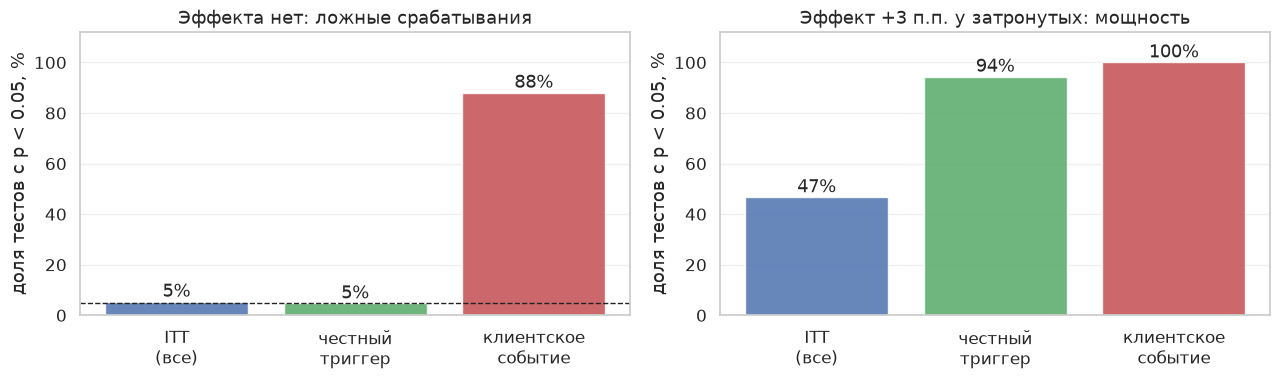

In [7]:
def trigger_trial(rng, effect, n=28_000):
    """Один тест: ITT, честный триггер и триггер по клиентскому событию. Возвращает (оценка, p-value) для каждого."""
    out = {}
    group = np.r_[np.zeros(n), np.ones(n)].astype(bool)
    android = rng.random(2 * n) < 0.40
    triggered = rng.random(2 * n) < 0.25
    p = np.where(triggered, 0.40 + effect * group, 0.30)
    converted = rng.random(2 * n) < p
    loss = np.where(group & android, np.where(converted, 0.10, 0.35), 0.02)
    logged = triggered & (rng.random(2 * n) >= loss)
    for name, mask in [('ITT', np.ones(2 * n, bool)), ('триггер', triggered), ('клиентское событие', logged)]:
        a, b = converted[mask & ~group], converted[mask & group]
        delta = b.mean() - a.mean()
        se = np.sqrt(a.var() / a.size + b.var() / b.size)
        out[name] = (delta, 2 * stats.norm.sf(abs(delta / se)), se)
    return out


rng = np.random.default_rng(7)
summary = {}
for effect in [0.0, 0.03]:
    trials = [trigger_trial(rng, effect) for _ in range(300)]
    for name in trials[0]:
        deltas = np.array([t[name][0] for t in trials])
        pvalues = np.array([t[name][1] for t in trials])
        summary[(name, effect)] = {'оценка, п.п.': deltas.mean() * 100, 'доля p < 0.05': (pvalues < 0.05).mean(),
                                   'SE, п.п.': np.mean([t[name][2] for t in trials]) * 100}
summary = pd.DataFrame(summary).T
display(summary.round(3))

names = ['ITT', 'триггер', 'клиентское событие']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, effect, title in [(axes[0], 0.0, 'Эффекта нет: ложные срабатывания'), (axes[1], 0.03, 'Эффект +3 п.п. у затронутых: мощность')]:
    values = [summary.loc[(name, effect), 'доля p < 0.05'] * 100 for name in names]
    ax.bar(['ITT\n(все)', 'честный\nтриггер', 'клиентское\nсобытие'], values, color=[BLUE, GREEN, RED], alpha=0.85)
    for k, value in enumerate(values):
        ax.text(k, value + 2, f'{value:.0f}%', ha='center')
    ax.set_ylim(0, 112)
    ax.set_ylabel('доля тестов с p < 0.05, %')
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].axhline(5, color='#222222', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

In [8]:
se_itt = summary.loc[('ITT', 0.03), 'SE, п.п.']
se_trig = summary.loc[('триггер', 0.03), 'SE, п.п.']
print(f"Разбавление: Δ_ITT ≈ Δ_trigger × 0.25 = 3.00 × 0.25 = 0.75 п.п. (симуляция ITT: {summary.loc[('ITT', 0.03), 'оценка, п.п.']:.2f})")
print(f"SE прямой ITT: {se_itt:.2f} п.п.; SE разбавленной оценки (SE_trigger × 0.25): {se_trig * 0.25:.2f} п.п. — в {se_itt / (se_trig * 0.25):.1f} раза уже")

# guardrail на старте: ошибка оплаты 2% в A. Что видно через 2 дня (n_B ≈ 3 000, n_A ≈ 12 000)?
n_a, n_b, p0 = 12_000, 3_000, 0.02
z = stats.norm.isf(0.001)                     # одностороннее p < 0.001: ловим поломку, а не эффект
se0 = np.sqrt(p0 * (1 - p0) * (1 / n_a + 1 / n_b))
for p1 in [0.03, 0.04, 0.06]:
    se1 = np.sqrt(p0 * (1 - p0) / n_a + p1 * (1 - p1) / n_b)
    power = stats.norm.sf((z * se0 - (p1 - p0)) / se1)
    print(f"Ошибка оплаты в B {p1:.0%} против {p0:.0%}: через 2 дня ловим с вероятностью {power:.0%}")

Разбавление: Δ_ITT ≈ Δ_trigger × 0.25 = 3.00 × 0.25 = 0.75 п.п. (симуляция ITT: 0.74)
SE прямой ITT: 0.40 п.п.; SE разбавленной оценки (SE_trigger × 0.25): 0.21 п.п. — в 1.9 раза уже
Ошибка оплаты в B 3% против 2%: через 2 дня ловим с вероятностью 64%
Ошибка оплаты в B 4% против 2%: через 2 дня ловим с вероятностью 100%
Ошибка оплаты в B 6% против 2%: через 2 дня ловим с вероятностью 100%


* **ITT честен, но слаб:** уровень значимости держит (~5%), а эффект, разбавленный в 4 раза, находит лишь в 47% тестов.
* **Честный триггер** держит уровень и находит эффект в 94% тестов: шум 75% незатронутых ушёл.
* **Триггер по клиентскому событию** ломает всё: при нулевом эффекте даёт в среднем +2.7 п.п. и «значимость» в 88% тестов. Разницу создаёт отбор (потерянные события у бросивших заказ), а не виджет.
* **Разбавленная оценка** $\Delta_{trigger} \times 0.25$ согласуется с ITT, но её SE почти вдвое меньше — в этом выигрыш триггера.

**Guardrail на старте.** Первые 1–2 дня смотрим не на эффект, а на поломки: SRM, потери событий, ошибки оплаты, падения, латентность. Порог строгий ($p < 0.001$), действие — остановить показ, а не «подождать». Через 2 дня рост ошибок оплаты с 2% до 4% виден почти наверняка, а до 3% — лишь в 64% случаев: грубые поломки ловятся быстро, тонкие ухудшения — только к концу теста.

## Итоги

* Группа — `hash(соль:user_id) mod 10 000`: детерминирована и воспроизводится вне платформы. Сверяйте лог с пересчитанным хешем.
* Своя соль у каждого теста и двойной посол в слоях; хеш — MD5/xxHash, а не CRC32/`hashCode` с `% 2`.
* A/A по солям: p-value равномерны, ~5% значимых; слишком ровные доли — тоже поломка.
* SRM — $\chi^2$ против заданного сплита, порог 0.001; при SRM эффект не считаем, ищем одну из пяти причин по срезам.
* Анализ — ITT или честный триггер, определённый одинаково в обеих группах до воздействия; события, теряемые по-разному, в метрики не берём.
* На практике: чистим `checkout_ab.csv`, проверяем SRM, расследуем пять SRM и считаем телеметрию, а итог сводим в чек-лист запуска `launch_checklist.md`.